# Data auto-labelling with Florence-2

<a href="https://colab.research.google.com/github/anyantudre/florence-2-cookbook/blob/main/2.%20Data%20auto-labelling%20with%20Florence-2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Use Florence-2 to label a folder of images automatically: run object detection (`<OD>`) on each image, then export the boxes as YOLO annotations you can use to train a detector.

## Install and import libraries

In [ ]:
!pip install -q -U "transformers>=5.13"

In [2]:
import os
import requests
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from transformers import AutoProcessor, Florence2ForConditionalGeneration

## Load Florence-2

In [3]:
model_id = 'florence-community/Florence-2-large'
# model_id = 'florence-community/Florence-2-base'  # smaller and faster

device = 'cuda' if torch.cuda.is_available() else 'cpu'
dtype = torch.float16 if device == 'cuda' else torch.float32

model = Florence2ForConditionalGeneration.from_pretrained(model_id, dtype=dtype).to(device).eval()
processor = AutoProcessor.from_pretrained(model_id)

In [4]:
def florence2(task_prompt, image, text_input=None):
    """Run one Florence-2 task on one image and return the parsed answer."""
    prompt = task_prompt if text_input is None else task_prompt + text_input
    inputs = processor(text=prompt, images=image, return_tensors="pt").to(device, dtype)

    generated_ids = model.generate(
        input_ids=inputs["input_ids"],
        pixel_values=inputs["pixel_values"],
        max_new_tokens=1024,
        do_sample=False,
        num_beams=3,
    )
    generated_text = processor.batch_decode(generated_ids, skip_special_tokens=False)[0]
    return processor.post_process_generation(
        generated_text,
        task=task_prompt,
        image_size=(image.width, image.height),
    )

## Download sample images

Replace this step with your own folder of images.

In [5]:
image_folder = 'images'
os.makedirs(image_folder, exist_ok=True)

sample_images = {
    'dog.jpeg': 'https://media.roboflow.com/notebooks/examples/dog.jpeg',
    'car.jpg': 'https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/car.jpg',
    'cats.jpg': 'http://images.cocodataset.org/val2017/000000039769.jpg',
}
for name, url in sample_images.items():
    with open(os.path.join(image_folder, name), 'wb') as f:
        f.write(requests.get(url).content)

sorted(os.listdir(image_folder))

['car.jpg', 'cats.jpg', 'dog.jpeg']

## Object detection

In [6]:
image = Image.open(os.path.join(image_folder, 'dog.jpeg')).convert('RGB')

od_results = florence2('<OD>', image)
od_results['<OD>']

{'bboxes': [[69, 247, 630, 928], [1, 353, 628, 1279]],
 'labels': ['dog', 'person']}

In [7]:
def plot_bbox(image, data):
    fig, ax = plt.subplots()

    # Display the image
    ax.imshow(image)

    # Plot each bounding box
    for bbox, label in zip(data['bboxes'], data['labels']):
        # Unpack the bounding box coordinates
        x1, y1, x2, y2 = bbox
        # Create a Rectangle patch
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=1, edgecolor='r', facecolor='none')
        # Add the rectangle to the Axes
        ax.add_patch(rect)
        # Annotate the label
        plt.text(x1, y1, label, color='white', fontsize=8, bbox=dict(facecolor='red', alpha=0.5))

    # Remove the axis ticks and labels
    ax.axis('off')

    # Show the plot
    plt.show()

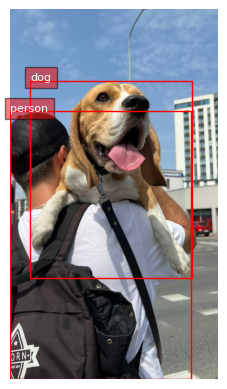

In [8]:
plot_bbox(image, od_results['<OD>']);

## Guided object detection

With `<CAPTION_TO_PHRASE_GROUNDING>`, you describe in text what to detect.

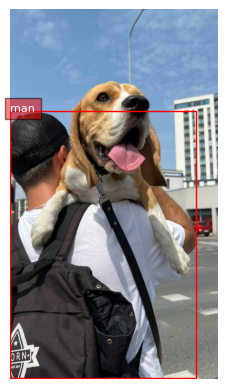

In [9]:
result = florence2('<CAPTION_TO_PHRASE_GROUNDING>', image, text_input='man')

plot_bbox(image, result['<CAPTION_TO_PHRASE_GROUNDING>']);

## Label a whole folder

Run `<OD>` on every image and save the raw results, one text file per image.

In [10]:
IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png')


def label_folder(folder_path, output_path, task_prompt='<OD>', text_input=None):
    """Run Florence-2 on every image in a folder.

    Saves one text file per image in `output_path` and returns
    {image_name: (result, (width, height))}.
    """
    os.makedirs(output_path, exist_ok=True)
    results = {}
    for image_name in sorted(os.listdir(folder_path)):
        if not image_name.lower().endswith(IMAGE_EXTENSIONS):
            continue
        try:
            image = Image.open(os.path.join(folder_path, image_name)).convert('RGB')
        except OSError:
            print(f'Failed to open image: {image_name}')
            continue

        result = florence2(task_prompt, image, text_input)[task_prompt]
        results[image_name] = (result, image.size)

        output_file = os.path.join(output_path, os.path.splitext(image_name)[0] + '.txt')
        with open(output_file, 'w') as f:
            for key, value in result.items():
                f.write(f'{key}: {value}\n')
        print(f'{image_name}: {len(result["bboxes"])} objects')
    return results


results = label_folder(image_folder, 'labels_raw')

car.jpg: 2 objects


cats.jpg: 5 objects


dog.jpeg: 2 objects


## Export to YOLO format

Each line of a YOLO label file is `<class_index> <x_center> <y_center> <width> <height>`, with coordinates relative to the image size (between 0 and 1).

By default, every label the model finds becomes a class, numbered in the order it first appears. The class list is saved in `classes.txt`. To keep only some classes, pass your own list, e.g. `export_yolo(results, 'labels_yolo', classes=['dog', 'cat'])`.

In [11]:
def to_yolo(bbox, image_width, image_height):
    xmin, ymin, xmax, ymax = bbox
    x_center = (xmin + xmax) / 2 / image_width
    y_center = (ymin + ymax) / 2 / image_height
    box_width = (xmax - xmin) / image_width
    box_height = (ymax - ymin) / image_height
    return f'{x_center:.6f} {y_center:.6f} {box_width:.6f} {box_height:.6f}'


def export_yolo(results, output_path, classes=None):
    """Write one YOLO label file per image, plus classes.txt.

    If `classes` is given, labels outside that list are skipped.
    Otherwise every detected label becomes a class.
    """
    os.makedirs(output_path, exist_ok=True)
    fixed_classes = classes is not None
    classes = list(classes) if fixed_classes else []

    for image_name, (result, (image_width, image_height)) in results.items():
        lines = []
        for bbox, label in zip(result['bboxes'], result['labels']):
            if label not in classes:
                if fixed_classes:
                    continue
                classes.append(label)
            lines.append(f'{classes.index(label)} {to_yolo(bbox, image_width, image_height)}')

        label_file = os.path.join(output_path, os.path.splitext(image_name)[0] + '.txt')
        with open(label_file, 'w') as f:
            f.write(''.join(line + '\n' for line in lines))

    with open(os.path.join(output_path, 'classes.txt'), 'w') as f:
        f.write(''.join(c + '\n' for c in classes))
    return classes


classes = export_yolo(results, 'labels_yolo')
print('classes:', classes)
print(open(os.path.join('labels_yolo', 'dog.txt')).read())

classes: ['car', 'door handle', 'cat', 'remote control', 'studio couch', 'dog', 'person']
5 0.485417 0.458984 0.779167 0.532031
6 0.436806 0.637500 0.870833 0.723437

